# 01 · Exploratory Data Analysis — Telco Customer Churn

**Goal:** understand *who* churns before building a model. Each chart ends with a one-sentence **business insight** written for a non-technical manager.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import FIGURES_DIR
from src.data_prep import clean_data, load_raw
from src.features import add_features

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
df = add_features(clean_data(load_raw()))
print(f"{len(df):,} customers | churn rate {df.Churn.mean():.1%}")
df.head()

7,043 customers | churn rate 26.5%


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group,avg_monthly_spend,num_services,is_month_to_month,auto_pay,charge_increase
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,Electronic check,29.85,29.85,0,0-12m,29.850000,1,1,0,0.000000
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,Mailed check,56.95,1889.50,0,25-48m,55.573529,3,0,0,1.376471
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,Mailed check,53.85,108.15,1,0-12m,54.075000,3,1,0,-0.225000
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,Bank transfer (automatic),42.30,1840.75,0,25-48m,40.905556,3,0,1,1.394444
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,Electronic check,70.70,151.65,1,0-12m,75.825000,1,1,0,-5.125000


## Data quality check

In [2]:
raw = load_raw()
print("Raw dtypes of TotalCharges:", raw.TotalCharges.dtype)
print("Blank TotalCharges:", (raw.TotalCharges.astype(str).str.strip() == "").sum(),
      "| all have tenure 0:", raw.loc[raw.TotalCharges.astype(str).str.strip() == "", "tenure"].eq(0).all())
print("Duplicate rows:", raw.duplicated().sum())
print("Missing values after cleaning:", df.isna().sum().sum())

Raw dtypes of TotalCharges: str
Blank TotalCharges: 11 | all have tenure 0: True
Duplicate rows: 0
Missing values after cleaning: 0


**Decision:** the 11 blank `TotalCharges` belong to brand-new customers (tenure = 0) who have not been billed yet, so they are set to 0 rather than dropped or mean-imputed.

## 1. Overall churn

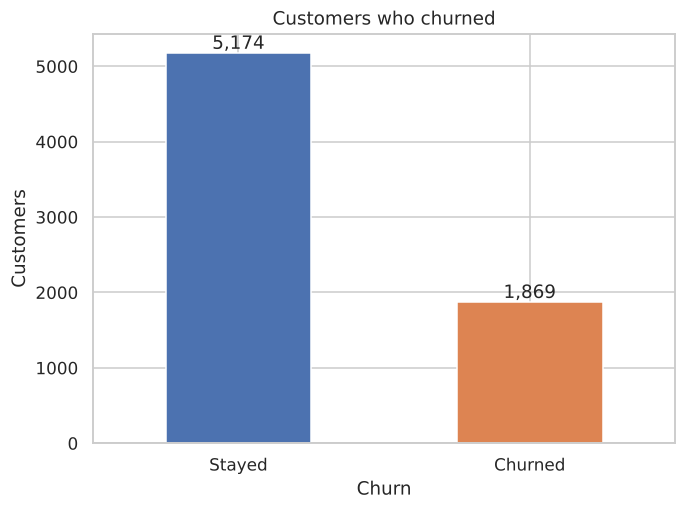

Monthly revenue from churned customers: $139,131 (31% of total)


In [3]:
ax = df.Churn.map({0: "Stayed", 1: "Churned"}).value_counts().plot.bar(color=["#4C72B0", "#DD8452"], rot=0)
ax.set_title("Customers who churned"); ax.set_ylabel("Customers")
for p in ax.patches: ax.annotate(f"{p.get_height():,}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_churn_overall.png"); plt.show()
lost_mrr = df.loc[df.Churn == 1, "MonthlyCharges"].sum()
print(f"Monthly revenue from churned customers: ${lost_mrr:,.0f} ({lost_mrr / df.MonthlyCharges.sum():.0%} of total)")

> **Insight:** About 1 in 4 customers (26.5%) left, taking roughly **$139k of monthly revenue (31%)** with them — churners pay more than average, so churn hurts revenue more than headcount suggests.

## 2. Churn rate by contract type

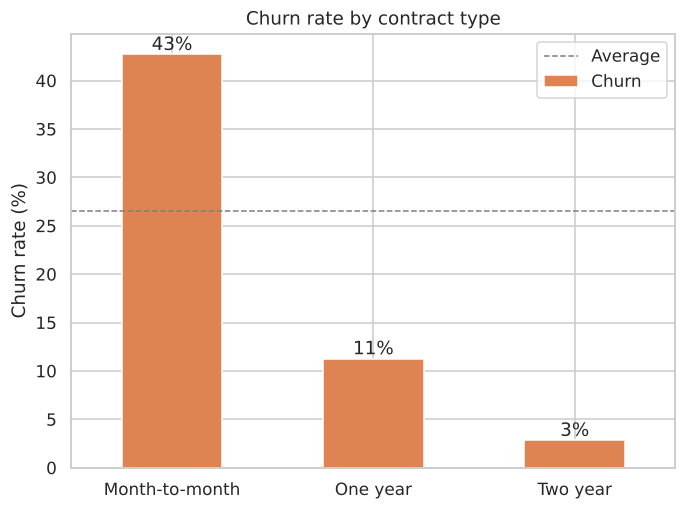

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64

In [4]:
def churn_bar(col, order=None, title=None, fname=None, rot=0):
    rate = df.groupby(col, observed=True).Churn.mean().mul(100)
    if order is not None: rate = rate.reindex(order)
    ax = rate.plot.bar(color="#DD8452", rot=rot)
    ax.set_ylabel("Churn rate (%)"); ax.set_xlabel(""); ax.set_title(title or f"Churn rate by {col}")
    ax.axhline(df.Churn.mean() * 100, ls="--", c="grey", lw=1, label="Average")
    for p in ax.patches: ax.annotate(f"{p.get_height():.0f}%", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
    ax.legend(); plt.tight_layout()
    if fname: plt.savefig(FIGURES_DIR / fname)
    plt.show(); return rate.round(1)

churn_bar("Contract", title="Churn rate by contract type", fname="eda_contract.png")

> **Insight:** Month-to-month customers churn at **43% vs 3% on two-year contracts** — moving customers onto longer contracts is the single biggest retention lever.

## 3. Churn rate by tenure

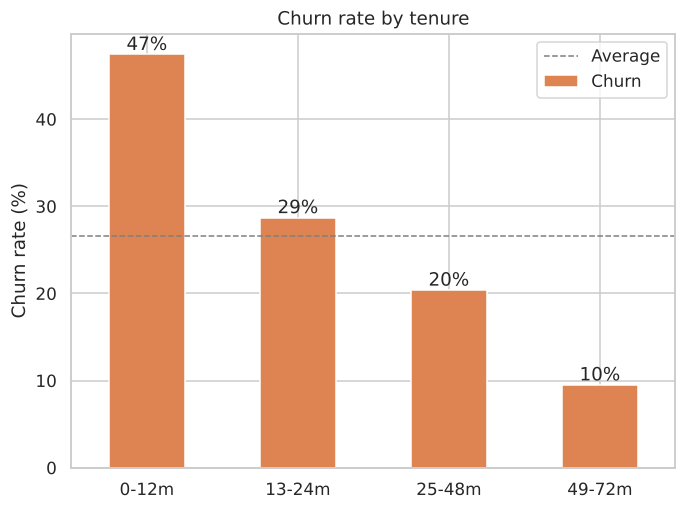

tenure_group
0-12m     47.4
13-24m    28.7
25-48m    20.4
49-72m     9.5
Name: Churn, dtype: float64

In [5]:
churn_bar("tenure_group", title="Churn rate by tenure", fname="eda_tenure.png")

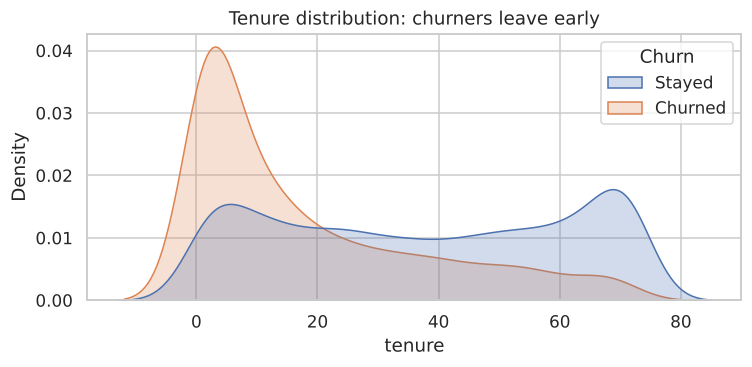

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.kdeplot(data=df, x="tenure", hue=df.Churn.map({0: "Stayed", 1: "Churned"}), fill=True, common_norm=False, ax=ax)
ax.set_title("Tenure distribution: churners leave early"); plt.tight_layout(); plt.show()

> **Insight:** Nearly **half of customers in their first year (47%) churn**, falling to 10% after four years — onboarding in the first 12 months is where retention budget pays off most.

## 4. Churn rate by monthly charges

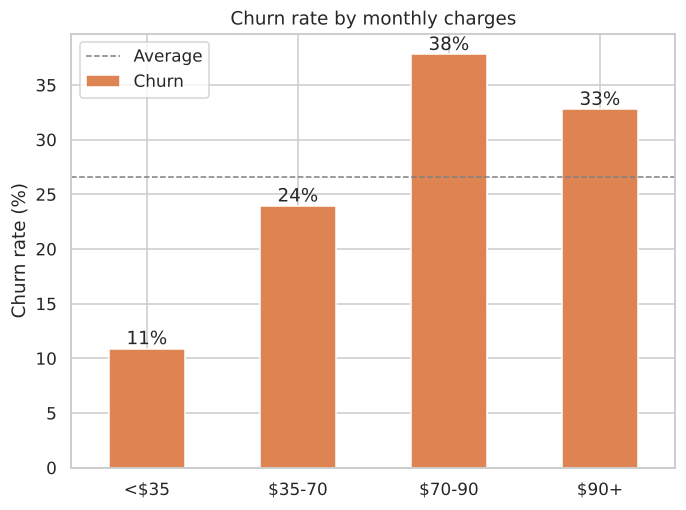

charge_band
<$35      10.9
$35-70    23.9
$70-90    37.8
$90+      32.8
Name: Churn, dtype: float64

In [7]:
df["charge_band"] = pd.cut(df.MonthlyCharges, [0, 35, 70, 90, 120], labels=["<$35", "$35-70", "$70-90", "$90+"])
churn_bar("charge_band", title="Churn rate by monthly charges", fname="eda_monthly_charges.png")

> **Insight:** Customers paying **$70–90/month churn at 38%, over 3× the rate of those under $35** — high-bill customers (mostly fiber) need a value check or loyalty pricing.

## 5. Churn rate by payment method

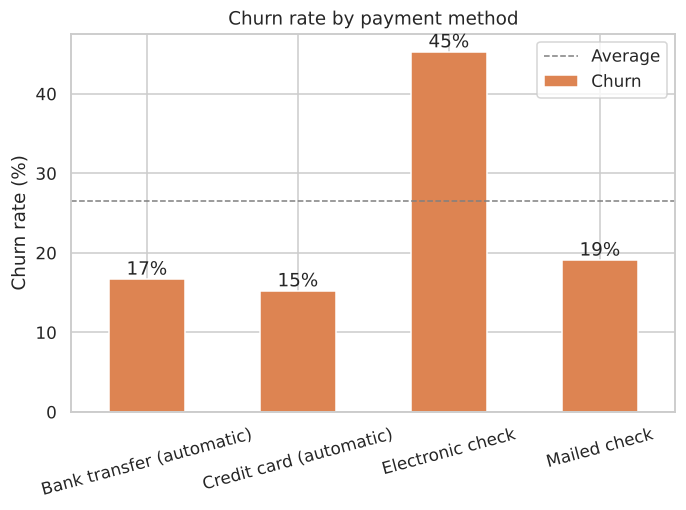

PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1
Name: Churn, dtype: float64

In [8]:
churn_bar("PaymentMethod", title="Churn rate by payment method", fname="eda_payment.png", rot=15)

> **Insight:** Electronic-check payers churn at **45% vs ~16% for automatic payments** — nudging customers to auto-pay is a cheap, low-friction retention action.

## 6. Support and services

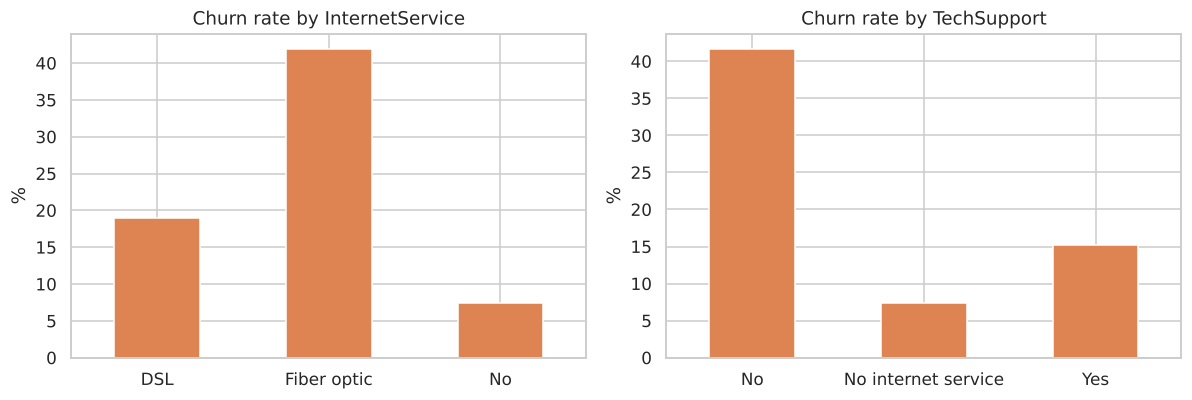

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col in zip(axes, ["InternetService", "TechSupport"]):
    r = df.groupby(col).Churn.mean().mul(100); r.plot.bar(ax=ax, color="#DD8452", rot=0)
    ax.set_title(f"Churn rate by {col}"); ax.set_ylabel("%"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_services.png"); plt.show()

> **Insight:** **49% of fiber-optic customers without tech support churn** (vs 23% of fiber customers with it), and overall churn is 15% with tech support vs 42% without, so bundling support is a strong protective offer.

## 7. Correlation of numeric features with churn

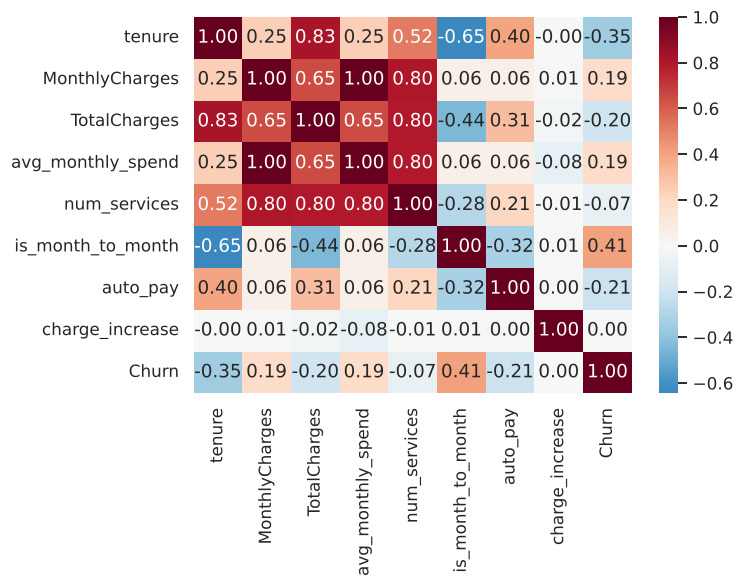

In [10]:
num = df[["tenure", "MonthlyCharges", "TotalCharges", "avg_monthly_spend", "num_services",
          "is_month_to_month", "auto_pay", "charge_increase", "Churn"]]
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_correlation.png"); plt.show()

> **Insight:** Contract type and tenure dominate; `tenure` and `TotalCharges` are highly correlated, which tree models handle well but we keep in mind for logistic regression.

## Summary for management

| Risk factor | Churn rate | Action |
|---|---|---|
| Month-to-month contract | 43% | Annual-contract discount |
| First 12 months | 47% | Onboarding programme |
| Electronic check | 45% | Auto-pay incentive |
| No tech support (with internet) | 42% | Free support trial |
| Fiber optic | 42% | Price / quality review |

Next: `src/train.py` turns these patterns into a predictive model.